# Climate Comfort Index: Random Forest experiment

Student **25945320**. Predicts the Climate Comfort Index at **+1, +2 and +3 days** from the leakage-audited feature
matrix built by the preprocessing notebook.

## Hypothesis

A Random Forest will beat persistence and climatology at all three horizons, and will prove more
robust than boosting at *t*+3, because averaging many decorrelated deep trees reduces variance
without fitting residual noise the way sequential boosting does.

The competing possibility is that bagging averages away the weak frontal signal that the deltas
and pressure-tendency features were engineered to supply, leaving a model that is really a
smoothed climatology. The ablation in section 4 and the prediction spread in section 6 test
that directly.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `RandomForestRegressor` | Low-variance ensemble, few assumptions, strong default behaviour on tabular data |
| Strategy | One model per horizon | Matches the deployed artefact layout and exposes per-horizon importances |
| Scaling | None | Trees split on thresholds |
| Tuning | Optuna TPE, 20 trials per horizon | Fewer interacting parameters than boosting, so a smaller budget suffices |
| Objective | Validation MAE, minimised | In CCI points, and robust to the rain-driven tail (see section 5) |

## Notebook structure

All ten experiment notebooks in this project follow the same ten sections and share their
machinery through `modeling.experiment` in the custom package, so results are directly
comparable and a change to a metric or a baseline applies everywhere at once.

| Section | Contents |
|---|---|
| 1 | Load the chronological splits (train and validation only) |
| 2 | Baselines |
| 3 | Model specification and default configuration |
| 4 | Feature-group ablation |
| 5 | Optuna hyperparameter optimisation |
| 6 | Final model and evaluation |
| 7 | Feature attribution |
| 8 | Generalisation check |
| 9 | Saved artefacts |
| 10 | Conclusions |

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# Trial count is overridable so the notebook can be smoke-tested quickly:
#   OPTUNA_TRIALS=5 jupyter nbconvert --execute ...
N_TRIALS = int(os.environ.get("OPTUNA_TRIALS", "25"))
SEED_CHECK = (RANDOM_STATE, 7, 2024)

EXPERIMENT = "cci_random_forest"
ALGORITHM_NAME = "Random Forest Regressor"
MODEL_LABEL = "random_forest"
MODEL_FAMILY = "sklearn"

task = xp.load_task("comfort_climate")
print(f"Task      : {task.target_name} ({task.kind})")
print(f"Experiment: {EXPERIMENT} - {ALGORITHM_NAME}")
print(f"Features  : {len(task.feature_columns)} across {len(task.feature_groups)} families")
print(f"Targets   : {', '.join(task.target_columns)}")
print(f"Optuna    : {N_TRIALS} trials per study, seed {RANDOM_STATE}")
print("\nRuntime note: the trial count is deliberately modest so the notebook completes in "
      "minutes\nrather than hours. Raise it with OPTUNA_TRIALS=100 once the notebook is known "
      "to run, and\nread the seed-stability table in section 5 before treating any extra trials "
      "as progress.")

Task      : Climate Comfort Index (regression)
Experiment: cci_random_forest - Random Forest Regressor
Features  : 105 across 8 families
Targets   : cci_t1, cci_t2, cci_t3
Optuna    : 25 trials per study, seed 25945320

Runtime note: the trial count is deliberately modest so the notebook completes in minutes
rather than hours. Raise it with OPTUNA_TRIALS=100 once the notebook is known to run, and
read the seed-stability table in section 5 before treating any extra trials as progress.


## 1. Load the chronological splits

Only the training and validation files are read. **The test split is never loaded in this
notebook.** It is reserved for a single final evaluation once one model has been selected across
all experiments, so that no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
embargo at each boundary. Nothing is re-split or shuffled. Features and targets live in separate
files and are aligned by the `feature_date` index, which `load_xy` verifies on every read.

In [2]:
X, y = {}, {}
for split in ("train", "val"):
    X[split], y[split] = task.load_xy(split)

if X["train"].index.max() >= X["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for split in ("train", "val"):
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")

train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28

Test split deliberately not loaded.


## 2. Baselines

Two reference forecasts. A model that fails to beat both is not worth deploying, whatever its
absolute error looks like.

**Persistence** carries today's CCI forward unchanged. It is the natural naive forecast for an
autocorrelated series and is strong at short horizons.

**Climatology** predicts the training-set average CCI for that day of the year, smoothed with a
15-day centred window to suppress sampling noise. It encodes the seasonal cycle and nothing else.
Centring is acceptable because the smoothing is applied to a day-of-year profile derived solely
from training data, not to the time series itself — no future observation enters any prediction.

The two are complementary: persistence knows the current weather but not the season, climatology
knows the season but not the weather. Beating both means the model has combined them.

In [3]:
BASELINE_PREDICTIONS = xp.regression_baselines(task, X, y)

rows = []
for target, forecasts in BASELINE_PREDICTIONS.items():
    for label, prediction in forecasts.items():
        rows.append({"target": target, "model": label,
                     **xp.regression_metrics(y["val"][target], prediction)})
BASELINES = pd.DataFrame(rows).set_index(["target", "model"])
BASELINE_MAE = {t: BASELINES.loc[(t, "persistence"), "mae"] for t in task.target_columns}

print("Validation baselines (the floors any model must clear):\n")
print(BASELINES.to_string())
print("\nObserved validation spread, for comparison with pred_std:")
print(y["val"][task.target_columns].std().to_string())

Validation baselines (the floors any model must clear):

                     mae   rmse     r2  pred_std
target model                                    
cci_t1 persistence 7.562  9.928  0.185    10.937
       climatology 7.627 10.135  0.151     3.723
cci_t2 persistence 8.624 11.521 -0.094    10.937
       climatology 7.640 10.141  0.152     3.722
cci_t3 persistence 9.162 12.015 -0.188    10.937
       climatology 7.651 10.143  0.153     3.720

Observed validation spread, for comparison with pred_std:
cci_t1   11.016
cci_t2   11.029
cci_t3   11.038


## 3. Model specification and default configuration

Everything specific to this algorithm lives in the next cell: how the estimator is built, the
default configuration, and the search space Optuna will sample. Every other section of this
notebook is shared with the other experiments, so a reader comparing two notebooks can diff this
one cell and know exactly what differs.

The default configuration is fitted and scored before any tuning. It is the reference against
which the Optuna result in section 6 is judged — a search that fails to improve on a sensible
default is a result worth reporting, not a step to skip.

In [4]:
def build_estimator(params: dict, seed: int = RANDOM_STATE) -> RandomForestRegressor:
    """Build a forest from a parameter dictionary."""
    return RandomForestRegressor(**{"n_jobs": -1, "random_state": seed, **params})


DEFAULT_PARAMS = {
    "n_estimators": 400, "max_depth": None, "min_samples_leaf": 2, "min_samples_split": 2,
    "max_features": 0.3,
}
ABLATION_PARAMS = {**DEFAULT_PARAMS, "n_estimators": 150}


def suggest_params(trial) -> dict:
    """Sample one candidate configuration.

    ``max_features`` is the parameter that matters most here. The feature matrix contains large
    blocks of near-duplicate columns — a variable, its lags and its rolling means — and a forest
    that considers all of them at every split produces highly correlated trees, which defeats the
    point of bagging. Low values force the trees apart. ``min_samples_leaf`` is the main
    complexity control on a dataset this small.
    """
    return {
        "n_estimators": trial.suggest_int("n_estimators", 150, 600, step=50),
        "max_depth": trial.suggest_categorical("max_depth", [None, 6, 10, 16, 24]),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "max_features": trial.suggest_float("max_features", 0.05, 1.0),
    }

In [5]:
def fit_model(params: dict, target: str, columns: list[str] | None = None,
              seed: int = RANDOM_STATE):
    """Fit one estimator for one horizon and return it with its predictions."""
    columns = columns or task.feature_columns
    model = build_estimator(params, seed)
    model.fit(X["train"][columns], y["train"][target])
    predictions = {split: model.predict(X[split][columns]) for split in ("train", "val")}
    return model, predictions


default_models, default_predictions = {}, {}
rows = []
for target in task.target_columns:
    model, predictions = fit_model(DEFAULT_PARAMS, target)
    default_models[target], default_predictions[target] = model, predictions["val"]
    rows.append({"target": target, "model": f"{MODEL_LABEL} (default)",
                 **xp.regression_metrics(y["val"][target], predictions["val"])})

DEFAULTS = pd.DataFrame(rows).set_index(["target", "model"])
print("Validation performance with the default configuration:\n")
print(DEFAULTS.to_string())
print("\nAgainst the persistence baseline (negative means the default already wins):")
for target in task.target_columns:
    delta = DEFAULTS.loc[(target, f"{MODEL_LABEL} (default)"), "mae"] - BASELINE_MAE[target]
    print(f"  {target}: MAE difference {delta:+.3f}")

Validation performance with the default configuration:

                                 mae  rmse    r2  pred_std
target model                                              
cci_t1 random_forest (default) 6.358 8.378 0.420     6.659
cci_t2 random_forest (default) 7.130 9.402 0.271     5.135
cci_t3 random_forest (default) 7.275 9.669 0.230     4.714

Against the persistence baseline (negative means the default already wins):
  cci_t1: MAE difference -1.204
  cci_t2: MAE difference -1.494
  cci_t3: MAE difference -1.887


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's CCI — and builds up. A
family that does not move validation error is not earning its place in the deployed model, and
dropping it produces a smaller artefact and a cleaner feature-importance table.

Default hyperparameters are used throughout this section so that differences are attributable to
the feature set rather than to tuning. Tuning comes next, on the full feature set, so the two
effects are never confounded. The ablation is scored on **validation** data only.

Validation MAE by cumulative feature set (lower is better):

target                   n_features  cci_t1  cci_t2  cci_t3
config                                                     
persistence only (cci)            1   7.728   8.712   9.447
+ same_day_observations           6   6.535   7.251   7.466
+ same_day_indices               17   6.293   7.404   7.466
+ lags                           49   6.263   7.192   7.376
+ rolling_statistics             89   6.365   7.130   7.266
+ rolling_precipitation          93   6.384   7.223   7.231
+ rolling_gusts                  97   6.361   7.143   7.256
+ deltas                        103   6.317   7.091   7.254
+ seasonal                      105   6.363   7.137   7.298


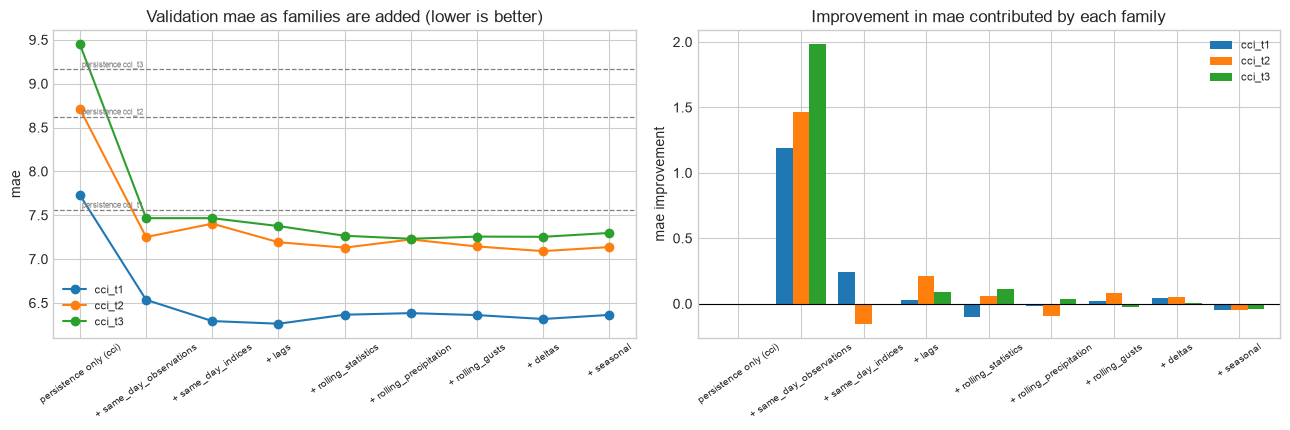

In [6]:
ABLATION_CONFIGS = xp.cumulative_feature_sets(task)


def ablation_score(columns: list[str], target: str) -> dict[str, float]:
    """Fit the default configuration on one feature subset and score it on validation."""
    _, predictions = fit_model(ABLATION_PARAMS, target, columns)
    return xp.regression_metrics(y["val"][target], predictions["val"])


ABLATION = xp.run_ablation(ABLATION_CONFIGS, ablation_score, task.target_columns)
fig, ABLATION_MAE = xp.plot_ablation(
    task, ABLATION, "mae", task.target_columns, f"{EXPERIMENT}-ablation",
    higher_is_better=False,
    reference={f"persistence {t}": v for t, v in BASELINE_MAE.items()},
)
ABLATION_MAE.insert(0, "n_features", [len(c) for c in ABLATION_CONFIGS.values()])
print("Validation MAE by cumulative feature set (lower is better):\n")
print(ABLATION_MAE.to_string())
plt.show()

## 5. Hyperparameter optimisation with Optuna

### Which metric is optimised, and why

The objective is **mean absolute error on the validation split**, minimised, with **one study per
horizon**.

*Why MAE rather than RMSE or R².* MAE is in CCI points, so an improvement of 0.4 is directly
readable as "four tenths of a comfort point closer, on average". RMSE squares the residual and is
therefore dominated by the rare heavy-rain days where `rain_score` saturates at zero and CCI
collapses; optimising it would tune the model for the tail at the expense of the ordinary days
that make up almost all of the distribution and almost all of the API's traffic. R² is a monotone
transform of MSE here and carries the same problem, plus it is scaled by the validation variance,
which makes values from different horizons incomparable.

*Why per horizon.* Three separate models are deployed, one per horizon, and predictability decays
with lead time. Optimising a single averaged score would let a strong *t*+1 configuration mask a
poor *t*+3 one. Separate studies also make the comparison of selected hyperparameters across
horizons a result in itself — regularisation that tightens as the horizon lengthens is evidence
of a weakening signal.

*Why validation and not cross-validation.* The split is chronological by design. A shuffled
k-fold would place future days in the training folds and inflate every score, because consecutive
days are strongly autocorrelated. The fixed 2024 validation period preserves the temporal
ordering and matches how the deployed model will be used: trained on the past, applied forward.

### The optimism this introduces, stated plainly

Validation data selects the hyperparameters and then reports the performance of the selection.
The reported validation MAE is therefore slightly better than a truly unseen estimate would be.
This is accepted rather than hidden: carving a third split from an already small training set
costs more in fitting data than it buys in cleanliness, and the honest final estimate comes from
the test split, which no notebook in this project has touched.

The seed-stability check below quantifies how much of the selected configuration's advantage is
real. If refitting the same hyperparameters under different random seeds moves validation MAE by
as much as the gap between the best and tenth-best trial, the search has been ranking noise and
the conclusion should say so.

In [7]:
def make_objective(target: str):
    """Return an Optuna objective that minimises validation MAE for one horizon."""
    def objective(trial) -> float:
        params = suggest_params(trial)
        model = build_estimator(params, RANDOM_STATE)
        model.fit(X["train"], y["train"][target])
        prediction = model.predict(X["val"])
        return float(np.mean(np.abs(np.asarray(y["val"][target]) - prediction)))
    return objective


STUDIES = {}
for target in task.target_columns:
    STUDIES[target] = xp.optimise(
        make_objective(target), n_trials=N_TRIALS, direction="minimize",
        seed=RANDOM_STATE, study_name=f"{EXPERIMENT}_{target}",
    )
    frame = xp.study_frame(STUDIES[target])
    print(f"{target}: best validation MAE {STUDIES[target].best_value:.4f} "
          f"from trial {STUDIES[target].best_trial.number} "
          f"({len(frame)} completed trials)")
    print(f"  best params: {STUDIES[target].best_params}")

BEST_PARAMS = {target: {**DEFAULT_PARAMS, **study.best_params}
               for target, study in STUDIES.items()}

print("\nTop five trials per horizon:\n")
for target, study in STUDIES.items():
    print(f"--- {target} ---")
    print(xp.study_frame(study).head(5).to_string(index=False))

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cci_t1: best validation MAE 6.3349 from trial 11 (25 completed trials)
  best params: {'n_estimators': 400, 'max_depth': 16, 'min_samples_leaf': 14, 'min_samples_split': 24, 'max_features': 0.23573757657148361}
cci_t2: best validation MAE 7.0383 from trial 0 (25 completed trials)
  best params: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 3, 'min_samples_split': 14, 'max_features': 0.9789821783658363}
cci_t3: best validation MAE 7.2440 from trial 22 (25 completed trials)
  best params: {'n_estimators': 550, 'max_depth': 24, 'min_samples_leaf': 1, 'min_samples_split': 37, 'max_features': 0.8880503181347932}

Top five trials per horizon:

--- cci_t1 ---
 trial  value  n_estimators  max_depth  min_samples_leaf  min_samples_split  max_features
    11  6.335           400     16.000                14                 24         0.236
    19  6.337           550     16.000                 5                 22         0.255
    15  6.338           450     16.000                 9

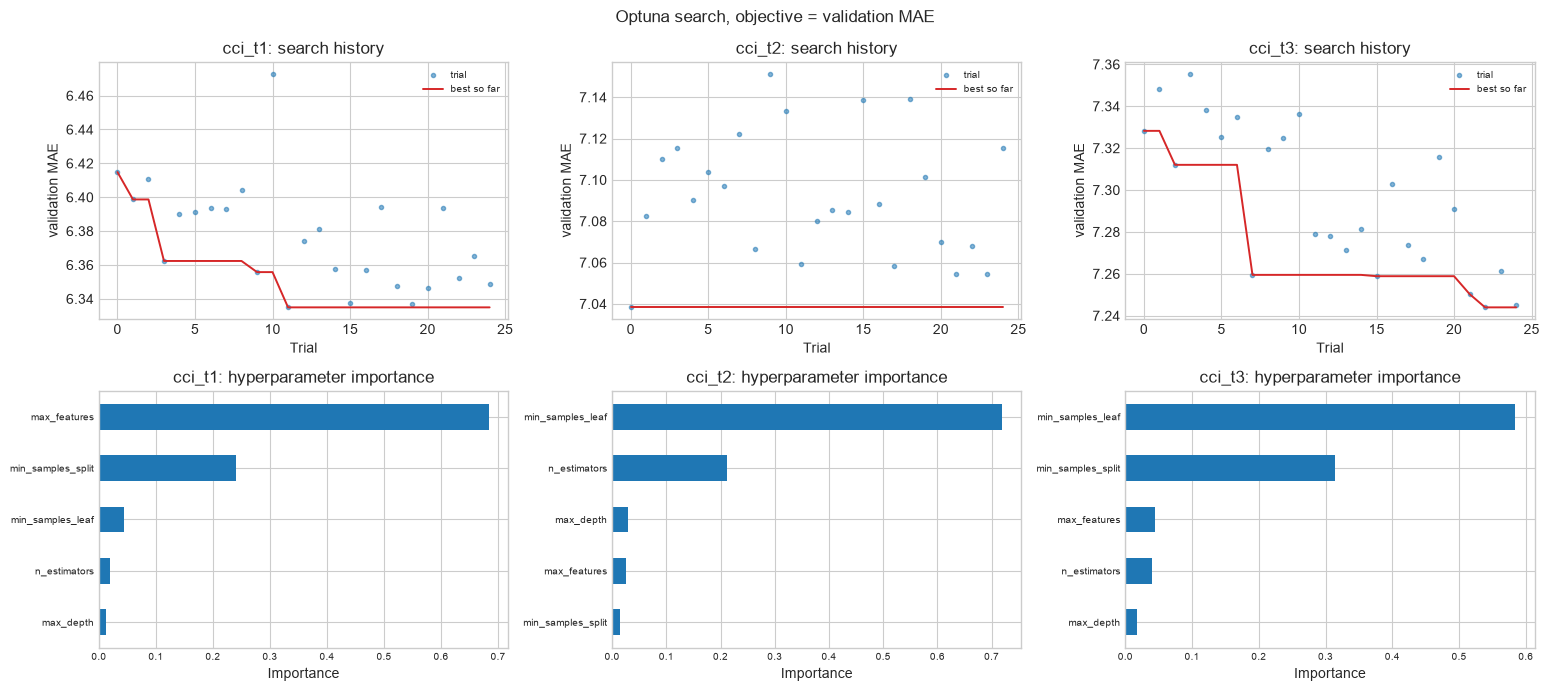

Seed-stability check (see the notes above for how to read `search_beats_noise`):

        best_trial_mae  seed_mean  seed_spread  top10_trial_spread  search_beats_noise
target                                                                                
cci_t1           6.335      6.348        0.031               0.023               False
cci_t2           7.038      7.049        0.040               0.044                True
cci_t3           7.244      7.252        0.030               0.034                True


In [8]:
xp.plot_optuna(task, STUDIES, "validation MAE", f"{EXPERIMENT}-optuna")
plt.show()

# How much of the best trial's advantage survives a change of random seed? If the seed spread is
# comparable to the spread across the top trials, the search ranked noise rather than signal.
stability_rows = []
for target, study in STUDIES.items():
    frame = xp.study_frame(study)
    top_spread = float(frame["value"].head(10).max() - frame["value"].head(10).min())
    seed_values = []
    for seed in SEED_CHECK:
        _, predictions = fit_model(BEST_PARAMS[target], target, seed=seed)
        seed_values.append(float(np.mean(np.abs(
            np.asarray(y["val"][target]) - predictions["val"]))))
    stability_rows.append({
        "target": target,
        "best_trial_mae": study.best_value,
        "seed_mean": float(np.mean(seed_values)),
        "seed_spread": float(np.max(seed_values) - np.min(seed_values)),
        "top10_trial_spread": top_spread,
        "search_beats_noise": float(np.max(seed_values) - np.min(seed_values)) < top_spread,
    })
STABILITY = pd.DataFrame(stability_rows).set_index("target")
print("Seed-stability check (see the notes above for how to read `search_beats_noise`):\n")
print(STABILITY.to_string())

## 6. Final models and evaluation against the baselines

The selected hyperparameters are refitted per horizon and scored against both baselines and
against the default configuration, so the notebook reports what tuning actually bought.

`pred_std` sits alongside the error metrics. It is the direct test for a model that has retreated
to predicting the mean: a spread far below the observed spread means the model is declining to
commit, which can produce a respectable MAE while being useless for identifying the uncomfortable
days a user actually cares about.

Expect error to grow with horizon. Atmospheric predictability decays, and the persistence
correlation measured during preprocessing fell sharply from *t*+1 to *t*+3, so a model that
performs equally well at all three horizons would be more suspicious than impressive.

Validation performance:

                                 mae   rmse     r2  pred_std  observed_std
target model                                                              
cci_t1 random_forest           6.335  8.405  0.416     6.382        11.016
       random_forest (default) 6.358  8.378  0.420     6.659        11.016
       persistence             7.562  9.928  0.185    10.937        11.016
       climatology             7.627 10.135  0.151     3.723        11.016
cci_t2 random_forest           7.038  9.374  0.276     5.209        11.029
       random_forest (default) 7.130  9.402  0.271     5.135        11.029
       persistence             8.624 11.521 -0.094    10.937        11.029
       climatology             7.640 10.141  0.152     3.722        11.029
cci_t3 random_forest           7.244  9.692  0.227     4.872        11.038
       random_forest (default) 7.275  9.669  0.230     4.714        11.038
       persistence             9.162 12.015 -0.188    10.937        11.038


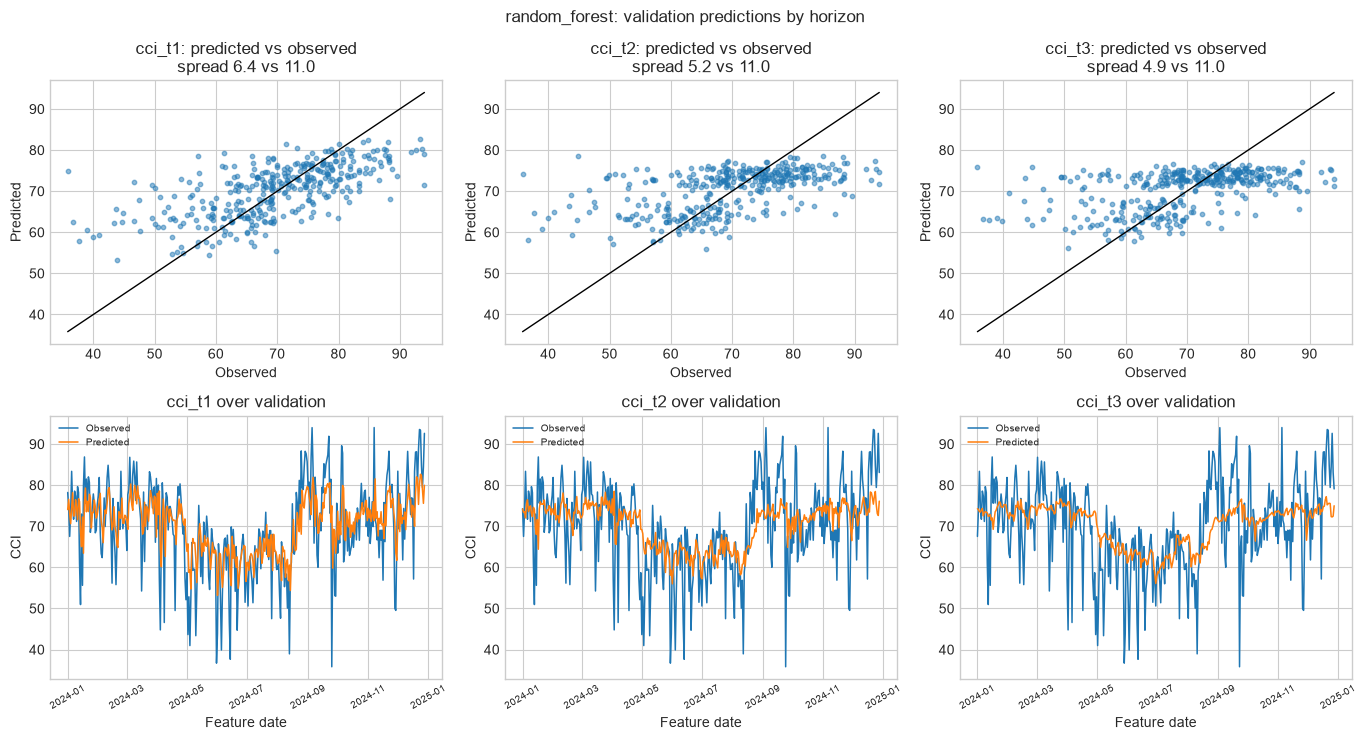

In [9]:
models, VAL_PREDICTIONS, TRAIN_PREDICTIONS = {}, {}, {}
rows = []
for target in task.target_columns:
    model, predictions = fit_model(BEST_PARAMS[target], target)
    models[target] = model
    VAL_PREDICTIONS[target] = predictions["val"]
    TRAIN_PREDICTIONS[target] = predictions["train"]
    rows.append({"target": target, "model": MODEL_LABEL,
                 **xp.regression_metrics(y["val"][target], predictions["val"])})
    rows.append({"target": target, "model": f"{MODEL_LABEL} (default)",
                 **xp.regression_metrics(y["val"][target], default_predictions[target])})
    for label, prediction in BASELINE_PREDICTIONS[target].items():
        rows.append({"target": target, "model": label,
                     **xp.regression_metrics(y["val"][target], prediction)})

RESULTS = pd.DataFrame(rows).set_index(["target", "model"])
RESULTS["observed_std"] = [float(y["val"][t].std()) for t in RESULTS.index.get_level_values(0)]
print("Validation performance:\n")
print(RESULTS.to_string())

comparison = []
for target in task.target_columns:
    tuned = RESULTS.loc[(target, MODEL_LABEL), "mae"]
    for reference in (f"{MODEL_LABEL} (default)", "persistence", "climatology"):
        baseline = RESULTS.loc[(target, reference), "mae"]
        comparison.append({"target": target, "reference": reference,
                           "mae_reduction": baseline - tuned,
                           "relative": (baseline - tuned) / baseline})
COMPARISON = pd.DataFrame(comparison).set_index(["target", "reference"])
print("\nImprovement over each reference (positive means the tuned model is better):\n")
print(COMPARISON.to_string(formatters={"relative": "{:.1%}".format}))

xp.plot_regression_validation(
    task, X["val"].index,
    {t: y["val"][t].to_numpy() for t in task.target_columns},
    VAL_PREDICTIONS, MODEL_LABEL, f"{EXPERIMENT}-validation",
)
plt.show()

## 7. Feature attribution

Impurity-based importances are read from the fitted per-horizon models and exported for the
`/model-metadata` endpoint.

One caveat governs how these should be read. Many of these features are strongly correlated —
`temperature_2m`, its four lags and its four rolling means all carry nearly the same signal. Tree
ensembles split that shared importance among the correlated group, so an individually
unimportant-looking feature may be part of a jointly essential block. Importance ranks features;
it does not prove any single one is dispensable. The ablation in section 4 is the more reliable
guide to what can be removed.

Comparing importances across horizons is informative in its own right. Features that rise in rank
from *t*+1 to *t*+3 are the ones carrying genuine forecast signal rather than persistence.

Total importance by family and horizon:

                       cci_t1  cci_t2  cci_t3
family                                       
deltas                  0.055   0.054   0.045
lags                    0.120   0.211   0.185
rolling_gusts           0.010   0.030   0.037
rolling_precipitation   0.012   0.028   0.034
rolling_statistics      0.360   0.498   0.524
same_day_indices        0.348   0.111   0.050
same_day_observations   0.078   0.029   0.031
seasonal                0.016   0.038   0.095

Share of total importance held by the top 10 features, per horizon:
  cci_t1: 52.3%
  cci_t2: 31.1%
  cci_t3: 33.5%


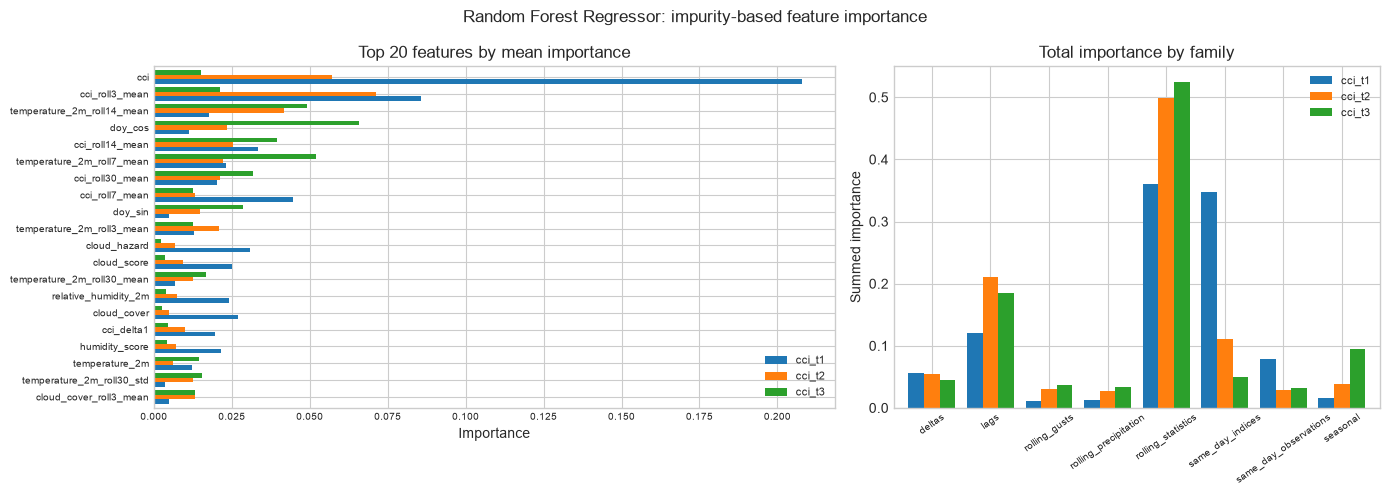

In [10]:
IMPORTANCES = pd.DataFrame(
    {target: pd.Series(models[target].feature_importances_, index=task.feature_columns)
     for target in task.target_columns}
)
fig, FAMILY_TOTALS = xp.plot_importance(
    task, IMPORTANCES, f"{EXPERIMENT}-importance",
    f"{ALGORITHM_NAME}: impurity-based feature importance",
)
print("Total importance by family and horizon:\n")
print(FAMILY_TOTALS.to_string())
print("\nShare of total importance held by the top 10 features, per horizon:")
for target in task.target_columns:
    share = IMPORTANCES[target].nlargest(10).sum() / IMPORTANCES[target].sum()
    print(f"  {target}: {share:.1%}")
plt.show()

## 8. Generalisation check

Training and validation error side by side. The ratio is the diagnostic: a value near 1 means the
model generalises, and a large value means it has fitted the training period in ways that do not
transfer to 2024.

Read this together with the seed-stability table in section 5. A model with a wide train-to-
validation gap *and* a large seed spread is not overfitting a fixable configuration — it is
fitting noise, which on this dataset points to weak signal rather than a tuning problem.

In [11]:
gap_rows = []
for target in task.target_columns:
    for split, prediction in (("train", TRAIN_PREDICTIONS[target]),
                              ("val", VAL_PREDICTIONS[target])):
        gap_rows.append({"target": target, "split": split,
                         **xp.regression_metrics(y[split][target], prediction)})

GAP = pd.DataFrame(gap_rows).set_index(["target", "split"])
print(GAP.to_string())

mae_gap = GAP["mae"].unstack()
mae_gap["val_to_train_ratio"] = mae_gap["val"] / mae_gap["train"]
print("\nValidation-to-training MAE ratio (near 1 means the model generalises):")
print(mae_gap.to_string())

               mae  rmse    r2  pred_std
target split                            
cci_t1 train 4.767 6.481 0.601     6.366
       val   6.335 8.405 0.416     6.382
cci_t2 train 3.558 4.954 0.767     6.468
       val   7.038 9.374 0.276     5.209
cci_t3 train 4.711 6.183 0.637     5.467
       val   7.244 9.692 0.227     4.872

Validation-to-training MAE ratio (near 1 means the model generalises):
split   train   val  val_to_train_ratio
target                                 
cci_t1  4.767 6.335               1.329
cci_t2  3.558 7.038               1.978
cci_t3  4.711 7.244               1.538


## 9. Saved artefacts

One model per horizon is written, together with a metadata document shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance,
selected hyperparameters and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since the estimator receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted.

The test split remains unused.

In [12]:
model_entries = []
for target in task.target_columns:
    horizon = int(target.rsplit("t", 1)[-1])
    model_entries.append({
        "target": task.target_name,
        "target_column": target,
        "prediction_type": "regression",
        "algorithm": ALGORITHM_NAME,
        "forecast_horizon": f"{horizon} Day{'s' if horizon > 1 else ''}",
        "hyperparameters": {k: (v if isinstance(v, (int, float, str, bool, type(None)))
                                else str(v)) for k, v in BEST_PARAMS[target].items()},
        "features": task.feature_columns,
        "feature_importance": {
            column: float(value) for column, value
            in IMPORTANCES[target].sort_values(ascending=False).head(20).items()
        } if not IMPORTANCES.empty else {},
        "validation_metrics": RESULTS.loc[(target, MODEL_LABEL)].drop("observed_std").to_dict(),
        "baseline_metrics": {
            reference: RESULTS.loc[(target, reference)].drop("observed_std").to_dict()
            for reference in ("persistence", "climatology")
        },
    })

METADATA = xp.build_metadata(
    task, EXPERIMENT, ALGORITHM_NAME, model_entries,
    best_params={t: {k: str(v) for k, v in p.items()} for t, p in BEST_PARAMS.items()},
    extra={
        "optimisation": {
            "library": "optuna",
            "objective": "validation mean absolute error",
            "direction": "minimize",
            "trials_per_study": N_TRIALS,
            "studies": list(STUDIES),
        },
        "seed_stability": STABILITY.reset_index().to_dict(orient="records"),
    },
)
bundle = xp.export_experiment(task, EXPERIMENT, models, METADATA, MODEL_FAMILY)
print(f"Saved bundle: {bundle.relative_to(PROJECT_ROOT)}")
print("\nThe test split has still not been touched. It should be used exactly once, after a")
print("single model has been selected on validation performance across all experiments.")

Saved bundle: models/comfort_climate/experiments/cci_random_forest

The test split has still not been touched. It should be used exactly once, after a
single model has been selected on validation performance across all experiments.


## 10. Conclusions

- **Against the baselines.** Section 6 is the headline. Beating persistence at *t*+1 is the
  hardest of the three, because persistence is strongest at short lead times.
- **Against boosting.** Compare validation MAE with the XGBoost notebook at each horizon. If the
  forest wins at *t*+3 and loses at *t*+1, that is a signal-to-noise story worth telling: boosting
  exploits structure where it exists and fits noise where it does not.
- **Dispersion.** A forest averages hundreds of trees, so `pred_std` well below `observed_std` is
  expected. Report how far below, because it bounds how useful the endpoint is for flagging
  genuinely uncomfortable days.

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all ten experiment notebooks.